# Introduction

The goal of this notebook is to present the model reduction method applied to a parametrized family of optimal transport problems. After describing this family of problems, we explain the principle of our method and appy it on a toy example. We then apply this method on a problem of color transfer.

### Authors
- Elise Bonnet-Weill
- Virginie Ehrlacher
- Luca Nenna

# Packages importations

In [1]:
# Maths packages
import numpy as np
import matplotlib.pyplot as plt
import random as rd
import scipy.optimize as opt
import scipy as sp
from time import time
import numpy.linalg as la
from numpy import transpose as t
from scipy.linalg import block_diag
pi = np.pi

import urllib.request

# Time measures
import time


# Packages for figures
import pandas as pd
import scipy.ndimage as sd
from matplotlib.gridspec import GridSpec
from PIL import Image
from fractions import Fraction




plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "legend.fontsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "lines.linewidth": 2,
})

plt.rcParams.update({
    'font.family': 'serif',
    'mathtext.fontset': 'cm',              # Computer Modern, matches LaTeX
    'axes.linewidth': 0.6,
    'pdf.fonttype': 42,                    # embed TrueType fonts (required by many publishers)
})
FIG_WIDTH = 7.0                            # inches: ~\textwidth of the paper
DPI = 600                                  # resolution of the thumbnails in the PDF
COLORS = ['#0072B2', '#D55E00', '#009E73'] # palettes 1, 2, 3 (colour-blind safe)

def thumb_hq(img, w_in):
    """uint8 image resampled (Lanczos) to w_in inches at DPI; never upsampled"""
    img = np.uint8(np.round(np.clip(img, 0, 1)*255))
    ih, iw = img.shape[:2]
    w_px = int(round(w_in*DPI))
    if w_px >= iw:
        return img
    return np.asarray(Image.fromarray(img).resize((w_px, max(1, round(w_px*ih/iw))), Image.LANCZOS))

# High-fidelity optimal transport problem

### Description

We begin by introducing the family of optimal transport problem we want to reduce.

Let $X= (x_1, \dots , x_{\mathcal{N}_x})$ and $Y = (y_1, \dots, y_{\mathcal{N}_y})$ be two discrete sets of size $\mathcal{N}_x$ and $\mathcal{N}_y$. Let $c:X\rightarrow Y$ be a cost function and $\mathbf{C} \in \mathbb{R}^{\mathcal{N}_x \times \mathcal{N}_y}$ the associated cost matrix:

\begin{equation}
 \mathbf{C}_{i, j}:= c(x_i, y_j) \text{ for } 1 \leq i \leq \mathcal{N}_x \text{ and } 1 \leq j \leq \mathcal{N}_y.  
\end{equation}

Let $\{\boldsymbol{\mu}_{k}\}_{1 \leq k \leq K_x}$ and  $\{\boldsymbol{\nu}_{l}\}_{1 \leq l \leq K_y}$ be two sets of discrete measures on $X$ and $Y$.
We define the set of parameters $\mathcal{A}$ by :

\begin{equation}
    \mathcal{A} := \{\boldsymbol{\alpha} = (\boldsymbol{\alpha}^{x}, \boldsymbol{\alpha}^{y}) \in \mathbf{R}_+^{K_x+ K_y}, \sum_{1 \leq k \leq K_x}\boldsymbol{\alpha}_{k}^x = 1, \sum_{1 \leq l \leq K_y}\boldsymbol{\alpha}_{l}^y = 1 \}.
\end{equation}

For a given parameter $\boldsymbol{\alpha} = (\boldsymbol{\alpha}^x, \boldsymbol{\alpha}^y) \in \mathcal{A}$, we define the parametrised measures $\boldsymbol{\mu}(\boldsymbol{\alpha})$ (respectively $\boldsymbol{\nu}(\boldsymbol{\alpha})$) as convex combinations of $\{\boldsymbol{\mu}_{k}\}_{1 \leq k \leq K_x}$ (resp.  $\{\boldsymbol{\nu}_{l}\}_{1 \leq l \leq K_y}$) with respect to the weights $\boldsymbol{\alpha}^x$ (resp. $\boldsymbol{\alpha}^y$):


\begin{equation}
    \begin{array}{cc}
      \displaystyle  \boldsymbol{\mu}(\boldsymbol{\alpha})= \sum_{1 \leq k \leq K_x} \boldsymbol{\alpha}^x_{k} \boldsymbol{\mu}_{k}  \\
       \displaystyle  \boldsymbol{\nu}(\boldsymbol{\alpha}) = \sum_{1 \leq \leq K_y} \boldsymbol{\alpha}^y_l \boldsymbol{\nu}_{l}.
    \end{array}
\end{equation}

The parametrized discrete optimal transport problem writes as follows:


\begin{equation}
I(\boldsymbol{\alpha}):= \mathop{\min}_{\begin{array}{ll}
& \boldsymbol{\Pi} \in \mathbb{R}_+^{\mathcal{N}_x \times \mathcal{N}_y} \\
& \displaystyle \sum_{j = 1}^{\mathcal{N}_y} \boldsymbol{\Pi}_{i,j} = \boldsymbol{\mu}_i(\boldsymbol{\alpha}) \text{ for } 1\leq i \leq \mathcal{N}_x \\
& \displaystyle \sum_{i = 1}^{\mathcal{N}_x} \boldsymbol{\Pi}_{i,j} = \boldsymbol{\nu}_j(\boldsymbol{\alpha}) \text{ for } 1\leq j \leq \mathcal{N}_y \\
\end{array}
}
\left\langle \boldsymbol{\Pi}, \mathbf{C} \right\rangle .
\end{equation}


In the present context, it will be more convenient to reformulate this problem in the standard form of linear programs. To do so, we cast $\boldsymbol{\Pi} \in \mathbb{R}_+^{\mathcal{N}_x \times \mathcal{N}_y}$ (respectively $\mathbf{C}\in \mathbb{R}_+^{\mathcal{N}_x \times \mathcal{N}_y}$) as a vector $\boldsymbol{\pi} \in \mathbb{R}_+^{\mathcal{N}_x \mathcal{N}_y}$ (resp. $\mathbf{c} \in \mathbb{R}+^{\mathcal{N}_x \mathcal{N}_y}$) by stacking its columns, and we define the matrix $\mathbf{A}$ that encodes the linear constraints.

The problem then writes in its standard form:


\begin{equation}
I({\boldsymbol{\alpha}}):= \mathop{\min}_{\begin{array}{c}
\boldsymbol{\pi} \in \mathbb{R}_+^{\mathcal{N}_x \mathcal{N}_y}\\
\mathbf{A} \boldsymbol{\pi} = \begin{pmatrix} \boldsymbol{\mu}(\boldsymbol{\alpha}) \\ \boldsymbol{\nu}(\boldsymbol{\alpha})\end{pmatrix}
\end{array}
}
\left\langle \boldsymbol{\pi}, \mathbf{c} \right\rangle .
\end{equation}

In the first part of this notebook, we consider that  $X \subset \mathbb{R}$, $Y \subset \mathbb{R}$ so that we solve 1-dimensional optimal transport problems. We also consider for  simplicity that $K_x = K_y = 2$.

### Choice of parameters

In the following cell, you can choose the discrete parameters defining the optimal transport problems :
- The discrete sets $X$ and $Y$ of size $\mathcal{N}_x$ and $\mathcal{N}_y$
- The discrete Cost $\mathbf{C}$
- The marginals $\boldsymbol{\mu}_0$, $\boldsymbol{\mu}_1$, $\boldsymbol{\nu}_0$ and $\boldsymbol{\nu}_1$

Note that $\mathcal{N}_x$ and $\mathcal{N}_y$ should not be too large (typically < 150) in order to be able to solve the high-fidelity problem on a commodity laptop.

In [3]:
# Discrete spaces X and Y
Le, Nx, Ny = 1, 50, 50
X, Y = np.linspace(-Le,Le,Nx), np.linspace(-Le,Le,Ny)

# Discrete Cost C (default : quadratic cost)
C = (X**2).reshape(Nx,1)@np.ones((1,Ny)) + np.ones((Nx,1))@(Y**2).T.reshape(1,Ny) - 2*X.reshape(Nx,1)@Y.T.reshape(1,Ny)

# Marginals (default : discrete gaussian measures, K0 = K1 = 2)
sigma_mu, sigma_nu = [0.5,0.5], [0.5,0.5]
m_mu, m_nu = [-Le/2,Le/2],  [-Le/2,Le/2]
K0, K1 = len(sigma_mu), len(sigma_nu)

mu0, mu1 = np.exp(-(X-m_mu[0]*np.ones((Nx)))**2/sigma_mu[0]**2), np.exp(-(X-m_mu[1]*np.ones((Nx)))**2/sigma_mu[1]**2)
nu0, nu1 = np.exp(-(Y-m_nu[0]*np.ones((Ny)))**2/sigma_nu[0]**2), np.exp(-(X-m_nu[1]*np.ones((Ny)))**2/sigma_nu[1]**2)
mu0, mu1, nu0, nu1 = mu0/np.sum(mu0), mu1/np.sum(mu1), nu0/np.sum(nu0), nu1/np.sum(nu1)

### Example of parametrized marginal

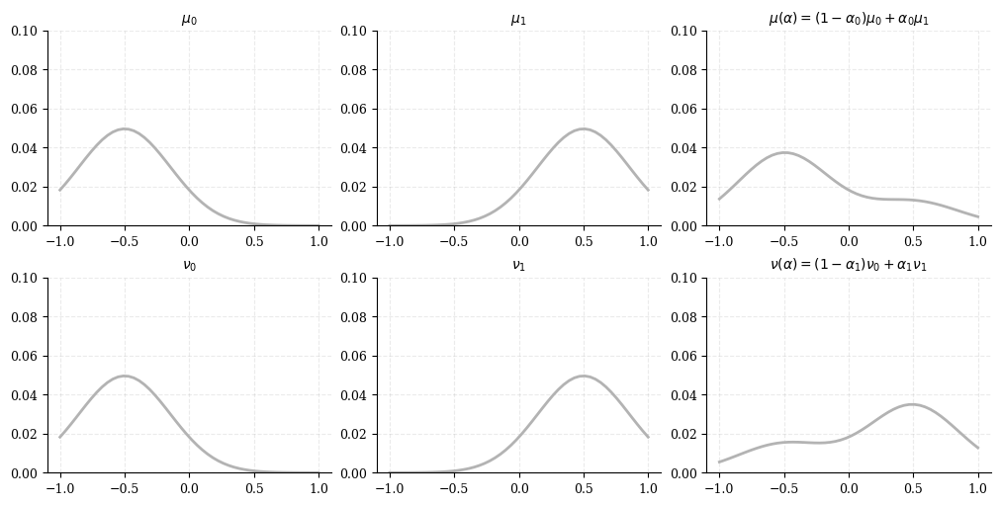

In [3]:
# Visualise the parametrized marginal

alpha_ex = [0.25, 0.7] # parameter chosen for the example
mu = (1 - alpha_ex[0]) * mu0 + alpha_ex[0] * mu1
nu = (1 - alpha_ex[1]) * nu0 + alpha_ex[1] * nu1

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(10, 5), constrained_layout=True)

grey = "0.7"  # Color for pictures

axes[0,0].plot(X, mu0, color=grey)
axes[0,0].set_title(r'$\mu_0$')

axes[0,1].plot(X, mu1, color=grey)
axes[0,1].set_title(r'$\mu_1$')

axes[0,2].plot(X, mu, color=grey)
axes[0,2].set_title(r'$\mu(\alpha) = (1-\alpha_0)\mu_0 + \alpha_0\mu_1$')

axes[1,0].plot(Y, nu0, color=grey)
axes[1,0].set_title(r'$\nu_0$')

axes[1,1].plot(Y, nu1, color=grey)
axes[1,1].set_title(r'$\nu_1$')

axes[1,2].plot(Y, nu, color=grey)
axes[1,2].set_title(r'$\nu(\alpha) = (1-\alpha_1)\nu_0 + \alpha_1\nu_1$')

for ax in axes.flat:
    ax.set_ylim(0, 0.1)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.show()

### Resolution of the high-fidelity problem


We use here two techniques of resolution of the high-fidelity problem : either we solve it as a linear program, or we use Sinkhorn algorithm.
Solving a linear program gives a more accurate solution (we will use it as reference solution), but in practice it is much slower than the solution obtained via Sinkhorn algorithm.

In what follows, given a test set of parameters $\mathcal{A}_{\text{test}}$, we compute the time of computation needed with both methods to get a solution, and compare the optimal values obtained.

In [4]:
# Test set
size_A_test= 50
A_test = np.zeros((size_A_test,2))

for ind in range(size_A_test):
    A_test[ind, 0] = rd.random()
    A_test[ind, 1] = rd.random()

In [5]:
# Linear Program

# Matrices defining the high-fidelity linear program
A= np.vstack([np.kron(np.eye(Nx),np.ones(Ny)), np.kron(np.ones(Nx), np.eye(Ny)) ])
c = np.matrix.flatten(C)
Apos = np.eye(Nx*Ny, Nx*Ny)
bpos = np.zeros(Nx*Ny)

HF_LP = np.zeros(size_A_test) # vector that stores the optimal values
k = 0
time_LP = 0
for alpha in A_test:
    a_mu, a_nu = alpha[0], alpha[1]
    t1_LP = time()
    mu, nu = (1-a_mu)*mu0 + a_mu*mu1, (1-a_nu)*nu0 + a_nu*nu1 # building the marginals
    munu = np.concatenate([mu,nu])
    options = {'dual_feasibility_tolerance': 1e-10, 'primal_feasibility_tolerance': 1e-10} # option for the linear programming solver
    res = opt.linprog(c, A_ub=- Apos, b_ub=bpos, A_eq=A, b_eq=munu, bounds=(None, None),x0=None, method='highs-ds', options = options)
    t2_LP = time()
    time_LP += t2_LP - t1_LP
    HF_LP[k] = res.fun # storing the optimal value
    k+=1
print("Time elapsed : ", time_LP)

Time elapsed :  3.4518749713897705


In [6]:
# Sinkhorn Algorithm

## Choosing Sinkhorn parameters
Nmax = 100
eps = 0.01
Ke = np.exp(-C/eps)


HF_S = np.zeros(size_A_test)
k = 0
time_S = 0
for alpha in A_test:
    a_mu, a_nu = alpha[0], alpha[1]
    t1_S = time()
    mu, nu = (1-a_mu)*mu0 + a_mu*mu1, (1-a_nu)*nu0 + a_nu*nu1 # uilding the marginals
    # Sinkhorn algorithm (here we fixed the number of iterations)
    g = np.ones(Ny)/Ny
    for t in range(Nmax):
        f = mu / (Ke@g)
        g = nu / (Ke.T@f)
    t2_S = time()
    time_S += t2_S - t1_S
    HF_S[k] = np.sum(np.matrix.flatten(np.diag(f)@(Ke*C)@np.diag(g))) # Storing optimal values
    k+=1
print("Time elapsed : ", time_S)


Time elapsed :  0.010879993438720703


In [8]:
print("Mean of the absolute difference of the optimal cost obtain via linear programming and via Sinkhorn :", np.mean(np.abs(HF_S - HF_LP)))

Mean of the absolute difference of the optimal cost obtain via linear programming and via Sinkhorn : 0.024455299168824596


# Reduced model


### Description of the model-order reduction


In this section, we present the formulation of the reduced-order model (ROM) designed to accelerate the resolution of parametrized optimal transport problems. The concept of this reduction method is the following: rather than searching for an optimal transport plan in the full high-fidelity space of dimension $N_x \times N_y$, we restrict the search space to a low-dimensional positive cone $\mathcal{W}_+$ generated by a small set of precomputed, high-fidelity snapshot solutions. By projecting the primal problem $(P_\alpha)$ onto this reduced cone spanned by our selected training plans $(\boldsymbol{\pi}(\boldsymbol{\alpha}_r))_{1 \le r \le R}$, we can reformulate the optimization problem using a lower-dimensional variable $\mathbf{p} \in \mathbb{R}^R_+$:

$$I_R(\boldsymbol{\alpha}) := \inf_{\hat{\boldsymbol{\pi}} \in \mathcal{W}_+} \left\{ \langle \hat{\boldsymbol{\pi}}, \mathbf{c} \rangle \quad \text{s.t.} \quad \mathbf{A}\hat{\boldsymbol{\pi}} = \begin{pmatrix} \boldsymbol{\mu}(\boldsymbol{\alpha}) \\ \boldsymbol{\nu}(\boldsymbol{\alpha}) \end{pmatrix} \right\}$$

Using the basis matrix representation $\hat{\boldsymbol{\pi}} = \mathbf{W}\mathbf{p}$ (where $\mathbf{W} \in \mathbb{R}^{(N_x N_y) \times R}$ columns are the stacked snapshot vectors), this problem is recast into the following reduced linear program:

$$I_{R}(\boldsymbol{\alpha}) := \inf_{\mathbf{p} \in \mathbb{R}^R_+} \left\{ \langle \mathbf{p}, \mathbf{W}^T\mathbf{c} \rangle \quad \text{s.t.} \quad \mathbf{A}\mathbf{W}\mathbf{p} = \begin{pmatrix} \boldsymbol{\mu}(\boldsymbol{\alpha}) \\ \boldsymbol{\nu}(\boldsymbol{\alpha}) \end{pmatrix} \right\} \tag{$RP_\alpha$}$$

*De facto reduction of the constraints*

While the formulation $(RP_{\boldsymbol{\alpha}})$ searches for a transport plan in a reduced cone, the constraint $\mathbf{A}\mathbf{W}\mathbf{p} = \begin{pmatrix} \boldsymbol{\mu}(\boldsymbol{\alpha}) \\ \boldsymbol{\nu}(\boldsymbol{\alpha}) \end{pmatrix}$ still involves $N_x + N_y$ equalities.

However, because the marginals depend linearly on the parameter, they are also reduced. Indeed, for every parameter $\boldsymbol{\alpha} \in \mathcal{A}$, we can decompose the marginals:

$$\boldsymbol{\mu}(\boldsymbol{\alpha}) = \sum_{k=1}^{K_x} \boldsymbol{\alpha}^x_k \boldsymbol{\mu}_k, \quad \boldsymbol{\nu}(\boldsymbol{\alpha}) = \sum_{k=1}^{K_y} \boldsymbol{\alpha}^y_k \boldsymbol{\nu}_k$$

Since each column of our reduced basis $\mathbf{W}$ satisfies the marginal constraints of the high-fidelity problem at its corresponding training parameter $\boldsymbol{\alpha}_r \in \mathcal{A}_{\text{train}}$, we have:

$$\mathbf{A}\mathbf{W}\mathbf{p} = \sum_{1 \le r \le R} p_r \begin{pmatrix} \boldsymbol{\mu}(\boldsymbol{\alpha}_r) \\ \boldsymbol{\nu}(\boldsymbol{\alpha}_r) \end{pmatrix} = \begin{pmatrix} \displaystyle \sum_{1 \le k \le K_x} \left( \sum_{1 \le r \le R} p_r \boldsymbol{\alpha}_{r, k}^x \right) \boldsymbol{\mu}_k \\ \displaystyle\sum_{1 \le k \le K_y} \left( \sum_{1 \le r \le R} p_r \boldsymbol{\alpha}_{r, k}^y \right) \boldsymbol{\nu}_k \end{pmatrix}$$

By linear independence of the reference measures, the constraint $\mathbf{A}\mathbf{W}\mathbf{p} = \begin{pmatrix} \boldsymbol{\mu}(\boldsymbol{\alpha}) \\ \boldsymbol{\nu}(\boldsymbol{\alpha}) \end{pmatrix}$ is mathematically equivalent to a much smaller system of only $K_x + K_y$ scalar constraints:

$$\sum_{1 \le r \le R} p_r \boldsymbol{\alpha}_{k, r}^x = \boldsymbol{\alpha}_k^x \quad \text{for } 1 \le k \le K_x, \quad \sum_{1 \le r \le R} p_r \boldsymbol{\alpha}_{k, r}^y = \boldsymbol{\alpha}_k^y \quad \text{for } 1 \le k \le K_y$$

We can recast this system in matrix form as $\mathbf{\hat{K}}\mathbf{p} = \boldsymbol{\alpha}$, where:

$$\mathbf{\hat{K}} = \begin{pmatrix} \boldsymbol{\alpha}_1 & \dots & \boldsymbol{\alpha}_R \end{pmatrix} \in \mathbb{R}^{(K_x + K_y) \times R}$$

This yields the final, highly efficient formulation:

$$\boxed{I_{R}(\boldsymbol{\alpha}):= \mathop{\min}_{\begin{array}{c}
\mathbf{p} \in \mathbb{R}_+^R\\
\mathbf{\hat{K}} \mathbf{p} = \boldsymbol{\alpha}
\end{array}
}
\left\langle \mathbf{p}, \mathbf{W}^T\mathbf{c} \right\rangle}$$

Since $K_x + K_y \ll N_x + N_y$ in typical applications, the effective number of constraints in $(RP_{\boldsymbol{\alpha}})$ is drastically reduced, with no need for any explicit reduction on the dual variables.

Note that $\hat{\mathbf{K}}$ is obtained without any computation, and $\mathbf{W}^T \mathbf{c} = ( I(\boldsymbol{\alpha}_1), ..., I(\boldsymbol{\alpha}_R)$).

### Implementation of the reduction

In [10]:
# Set of snapshots : A_train - A grid over the square [0;1]^2
nb_snap_mu, nb_snap_nu = 5, 7
P = nb_snap_mu * nb_snap_nu
A_train = np.zeros((2,P))
A_train[0,:] = np.matrix.flatten(np.ones((nb_snap_nu, 1))@np.reshape(np.linspace(0,1,nb_snap_mu), (1,nb_snap_mu)))
A_train[1,:] = np.matrix.flatten(np.reshape(np.linspace(0,1,nb_snap_nu), (nb_snap_nu,1))@np.ones((1, nb_snap_mu)))

In [12]:
# Building K
K = np.vstack([A_train, np.ones(P)])

In [14]:
# Building W^Tc with LP (it may take some time)
Wc_LP = np.zeros(P)
W_LP = np.zeros((P, Nx*Ny))

for p in range(P):
    a_mu, a_nu = A_train[0,p], A_train[1, p]
    options = {'dual_feasibility_tolerance': 1e-10, 'primal_feasibility_tolerance': 1e-10}
    mu, nu = (1-a_mu)*mu0 + a_mu*mu1, (1-a_nu)*nu0 + a_nu*nu1
    munu = np.concatenate([mu,nu])
    res = opt.linprog(c, A_ub=- Apos, b_ub=bpos, A_eq=A, b_eq=munu, bounds=(None, None),x0=None, method='highs-ds', options = options)
    Wc_LP[p] = res.fun
    W_LP[p,:] = np.matrix.flatten(res.x)


In [15]:
# Building W^Tc with Sinkhorn
# Sinkhorn Algorithm
Nmax = 100
eps = 0.01
Ke = np.exp(-C/eps)


Wc_S = np.zeros(P)
W_S = np.zeros((P, Nx*Ny))

for p in range(P):
    a_mu, a_nu = A_train[0,p], A_train[1, p]
    mu, nu = (1-a_mu)*mu0 + a_mu*mu1, (1-a_nu)*nu0 + a_nu*nu1
    # Sinkhorn
    g = np.ones(Ny)/Ny
    for t in range(Nmax):
        f = mu / (Ke@g)
        g = nu / (Ke.T@f)
    Wc_S[p] = np.sum(np.matrix.flatten(np.diag(f)@(Ke*C)@np.diag(g)))
    W_S[p,:] = np.matrix.flatten(np.diag(f)@(Ke)@np.diag(g))


### Resolution of reduced-order model

We now solve the reduced-order models obtained. We first compare the time and precision obtained on $\mathcal{A}_{\text{test}}$.

In [17]:
# Resolution of the reduced-order model with LP snapshots
RB_LP = np.zeros(size_A_test)
k = 0
time_RB_LP = 0
for alpha in A_test:
    t1_S = time()
     # Solving the reduced problem
    res = opt.linprog(Wc_LP, A_ub=-np.eye(P), b_ub=np.zeros(P), A_eq=K, b_eq=[alpha[0],alpha[1],1], bounds=(None, None),x0=None, method='highs-ds', options = options)
    t2_S = time()
    time_RB_LP += t2_S - t1_S
    RB_LP[k] = res.fun
    k+=1
print("Time elapsed : ", time_RB_LP)

Time elapsed :  0.07527422904968262


In [18]:
# Resolution of the reduced-order model with Sinkhorn snapshots
RB_S = np.zeros(size_A_test)
k = 0
time_RB_S = 0
for alpha in A_test:
    # Solving the reduced problem
    res = opt.linprog(Wc_S, A_ub=-np.eye(P), b_ub=np.zeros(P), A_eq=K, b_eq=[alpha[0],alpha[1],1], bounds=(None, None),x0=None, method='highs-ds', options = options)
    t2_S = time()
    time_RB_S += t2_S - t1_S
    RB_S[k] = res.fun
    k+=1
print("Time elapsed : ", time_RB_S)

Time elapsed :  20.165716886520386


In [20]:
print("Gap between high-fidelity LP and high-fidelity Sinkhorn :", np.mean(np.abs(HF_S - HF_LP)))
print("Gap between high-fidelity LP and reduced-bases (LP snapshots) :", np.mean(np.abs(RB_LP - HF_LP)))
print("Gap between high-fidelity LP and reduced-bases (Sinkhorn snapshots) :", np.mean(np.abs(RB_S - HF_LP)))


Gap between high-fidelity LP and high-fidelity Sinkhorn : 0.029505763915299226
Gap between high-fidelity LP and reduced-bases (LP snapshots) : 0.006198493635555722
Gap between high-fidelity LP and reduced-bases (Sinkhorn snapshots) : 0.021453894942968472


### Visual comparison of the shapes of the transport plans

Then, for a given parameter $\boldsymbol{\alpha}$, we compute and then compare the transport plan obtained with each method.

In [21]:
# Computation of transport plans obtained with each method at a fixed parameter

# !!! Choose the parametrized marginals !!
a_mu, a_nu = 0.73, 0.28

#Building the marginals
mu, nu = (1-a_mu)*mu0 + a_mu*mu1, (1-a_nu)*nu0 + a_nu*nu1
munu = np.concatenate([mu,nu])
Umu, Unu = (1-a_mu)*Umu0 + a_mu*Umu1, (1-a_nu)*Vnu0 + a_nu*Vnu1
Umunu = np.hstack([Umu, Unu])

# LP solution
res = opt.linprog(c, A_ub=- Apos, b_ub=bpos, A_eq=A, b_eq=munu, bounds=(None, None),x0=None, method='highs-ds', options = options)
P_LP = np.reshape(res.x, (Nx, Ny))

# Sinkhorn solution
g = np.ones(Ny)/Ny
for t in range(Nmax):
    f = mu / (Ke@g)
    g = nu / (Ke.T@f)
P_S = np.diag(f)@(Ke)@np.diag(g)

# Reduced base with LP snapshots  solution
#res_LP = opt.linprog(Wc_LP, A_ub=-np.eye(P), b_ub=np.zeros(P), A_eq=(S.T)@WA, b_eq=Umunu, bounds=(None, None),x0=None, method='highs-ds', options = options)
res_LP = opt.linprog(Wc_LP, A_ub=-np.eye(P), b_ub=np.zeros(P), A_eq=K, b_eq=[a_mu, a_nu,1], bounds=(None, None),x0=None, method='highs-ds', options = options)
P_RB_LP = np.reshape(W_LP.T@res_LP.x, (Nx, Ny))
# Reduced base with Sinkhorn snapshots  solution
#res_S = opt.linprog(Wc_S, A_ub=-np.eye(P), b_ub=np.zeros(P), A_eq=(S.T)@WA, b_eq=Umunu, bounds=(None, None),x0=None, method='highs-ds', options = options)
res_S = opt.linprog(Wc_S, A_ub=-np.eye(P), b_ub=np.zeros(P), A_eq=K, b_eq=[a_mu, a_nu,1], bounds=(None, None),x0=None, method='highs-ds', options = options)
P_RB_S = np.reshape(W_S.T@res_S.x, (Nx, Ny))


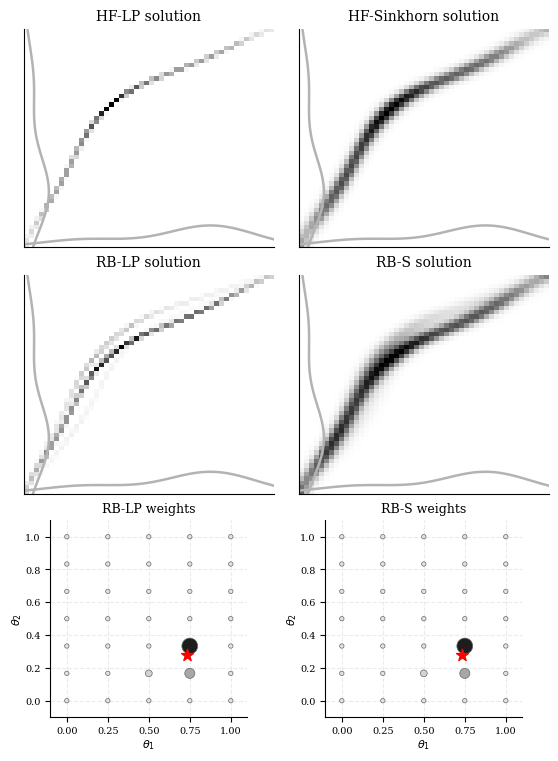

In [22]:
# Visual comparison of transport plans obtained with each method + RB weights
plt.close()

fig, axes = plt.subplots(
    3, 2, figsize=(5.5, 7.5), constrained_layout=True,
    gridspec_kw={"height_ratios": [1, 1, 0.9]}
)

normal = 0.2

# Plot marginals on the transport-plan axes only (rows 0 and 1)
for ax in axes[:2].flatten():
    ax.set_xticks([])
    ax.set_yticks([])
    ax.plot(X, mu/mu.max()*normal - Le, color=grey, linewidth=1.8)
    ax.plot(nu/nu.max()*normal - Le, Y, color=grey, linewidth=1.8)

# Colormaps
cmap_HF = plt.cm.Greys
cmap_RB = plt.cm.Greys

imshow_kw = dict(
    origin="lower",
    extent=[X.min(), X.max(), Y.min(), Y.max()],
    interpolation="nearest",
    aspect="auto",
)

# --- Rows 0-1: transport plans ---
axes[0, 0].imshow(P_LP,    cmap=cmap_HF, **imshow_kw); axes[0, 0].set_title("HF-LP solution")
axes[0, 1].imshow(P_S,     cmap=cmap_HF, **imshow_kw); axes[0, 1].set_title("HF-Sinkhorn solution")
axes[1, 0].imshow(P_RB_LP, cmap=cmap_RB, **imshow_kw); axes[1, 0].set_title("RB-LP solution")
axes[1, 1].imshow(P_RB_S,  cmap=cmap_RB, **imshow_kw); axes[1, 1].set_title("RB-S solution")


# --- Row 2: weights of the snapshots in the parameter plane ---
def plot_weights(ax, weights, title):
    weights = np.ravel(np.asarray(weights))[:P]   # first P entries = snapshot weights
    w = np.abs(weights)
    w_norm = w / (w.max() + 1e-12)
    colors = [plt.cm.Greys(0.2 + 0.7 * wi) for wi in w_norm]
    sizes = 10 + 120 * w_norm

    ax.scatter(A_train[0], A_train[1], color=colors, s=sizes,
               edgecolors="0.4", linewidths=0.5, zorder=2)
    ax.scatter(a_mu, a_nu, color="red", marker="*", s=80, zorder=3)
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1.1)
    ax.set_aspect("equal")
    ax.set_xlabel(r"$\theta_1$", fontsize=8, labelpad=1)
    ax.set_ylabel(r"$\theta_2$", fontsize=8, labelpad=1)
    ax.tick_params(labelsize=7)
    ax.set_title(title, fontsize=9)

plot_weights(axes[2, 0], res_LP.x, "RB-LP weights")
plot_weights(axes[2, 1], res_S.x,  "RB-S weights")

plt.show()

# Application : Reduced-bases for a color transfer problem
In this part, we apply the model order reduction method to solve efficiently a color transfer problem. Our goal is to transfer the color distribution of an image to a parametrized color distribution (obtained by convex combination of two color distribution)

This application is a generalization of the transfer color problem proposed in the notebook "Color transfer with regularized optimal transport" of the Storimaging website :
https://storimaging.github.io/notebooksContrastAndColor/

### Load and Display images & set parameters

" # VERSION WITH POINT CLOUDS\n# pictures + colour clouds below each picture (second file)\nfig = plt.figure(figsize=(12, 15))\ngs = GridSpec(4, 3, figure=fig, height_ratios=[1, 1.1, 1, 1.1], hspace=0.15, wspace=0.05)\nlayout = [((0, 1), (1, 1), imsrc,  im0, 'Image'),\n          ((2, 0), (3, 0), imtgt1, im1, 'target palette 1'),\n          ((2, 1), (3, 1), imtgt2, im2, 'target palette 2'),\n          ((2, 2), (3, 2), imtgt3, im3, 'target palette 3')]\nfor (ri, ci), (rc, cc), img, im_q, title in layout:\n    ax = fig.add_subplot(gs[ri, ci])\n    ax.imshow(img)\n    ax.set_title(title)\n    ax.axis('off')\n    plot_color_cloud(fig.add_subplot(gs[rc, cc], projection='3d'), im_q, N)\nfig.savefig('images_palettes_and_clouds.pdf', dpi=300, bbox_inches='tight', pad_inches=0.05)\nplt.show()\n"

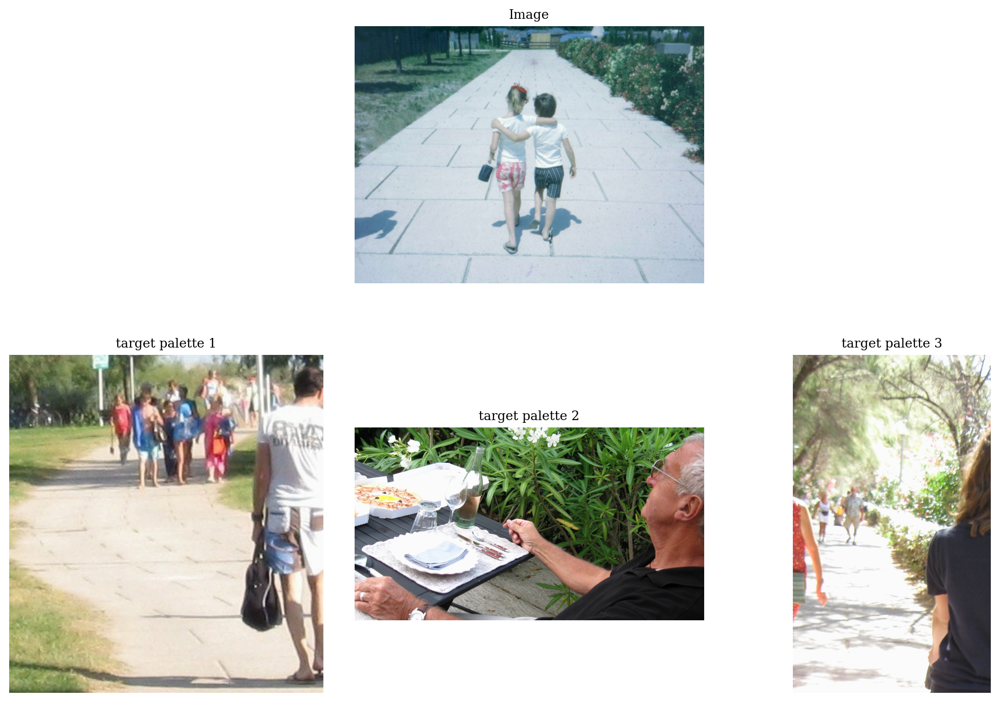

In [28]:
## Import images
imsrc  = plt.imread('Photos/3P.jpg')/255
imtgt1 = plt.imread('Photos/GM4.JPG')/255
imtgt2 = plt.imread('Photos/GM12.JPG')/255
imtgt3 = plt.imread('Photos/GM7.JPG')/255


N = 64    # histogram on a N x N x N uniform grid

# probability vectors
im1 = np.floor(np.double(imtgt1*(N-0.01)))   # target palette 1
im2 = np.floor(np.double(imtgt2*(N-0.01)))   # target palette 2
im3 = np.floor(np.double(imtgt3*(N-0.01)))   # target palette 3
im0 = np.floor(np.double(imsrc*(N-0.01)))    # image to recolor

# we display the images: the image on top, the 3 target palettes below
fig, axes = plt.subplot_mosaic([['.',  'src', '.'],
                                ['t1', 't2',  't3']],
                               figsize=(12, 8))
for key, im, title in [('src', im0, 'Image'),
                       ('t1', im1, 'target palette 1'),
                       ('t2', im2, 'target palette 2'),
                       ('t3', im3, 'target palette 3')]:
    axes[key].imshow(im/N)
    axes[key].axis('off')
    axes[key].set_title(title)
fig.tight_layout()
fig.savefig('images_and_palettes.pdf', bbox_inches='tight', pad_inches=0.02)


# For a Figure with a RBG repreesntation of the color histograms
def plot_color_cloud(ax, im_q, N, max_size=40, elev=22, azim=-58):
    """3D histogram of the colours on the N x N x N grid (the discrete measure used by OT):
    one point per non-empty bin, drawn in its own colour, area proportional to its mass"""
    idx, counts = np.unique(im_q.reshape(-1, 3).astype(int), axis=0, return_counts=True)
    pts = (idx + 0.5) / N                              # bin centres in [0,1]^3
    w = counts / counts.sum()
    order = np.argsort(w)                              # heavy bins drawn last (on top)
    pts, w = pts[order], w[order]
    ax.scatter(pts[:,0], pts[:,1], pts[:,2], c=pts, s=max_size*np.sqrt(w/w.max()) + 0.3,
               linewidths=0, alpha=0.9, depthshade=False, rasterized=True)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_zlim(0, 1)
    ax.set_xticks([0, 0.5, 1]); ax.set_yticks([0, 0.5, 1]); ax.set_zticks([0, 0.5, 1])
    ax.tick_params(labelsize=6, pad=0)
    ax.set_xlabel('R', fontsize=8, labelpad=-8); ax.set_ylabel('G', fontsize=8, labelpad=-8)
    ax.set_zlabel('B', fontsize=8, labelpad=-8)
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_pane_color((1, 1, 1, 0))
        axis._axinfo['grid'].update(color=(0.85, 0.85, 0.85), linewidth=0.4)
    ax.view_init(elev=elev, azim=azim)
    ax.set_box_aspect((1, 1, 1), zoom=1.2)
""" # VERSION WITH POINT CLOUDS
# pictures + colour clouds below each picture (second file)
fig = plt.figure(figsize=(12, 15))
gs = GridSpec(4, 3, figure=fig, height_ratios=[1, 1.1, 1, 1.1], hspace=0.15, wspace=0.05)
layout = [((0, 1), (1, 1), imsrc,  im0, 'Image'),
          ((2, 0), (3, 0), imtgt1, im1, 'target palette 1'),
          ((2, 1), (3, 1), imtgt2, im2, 'target palette 2'),
          ((2, 2), (3, 2), imtgt3, im3, 'target palette 3')]
for (ri, ci), (rc, cc), img, im_q, title in layout:
    ax = fig.add_subplot(gs[ri, ci])
    ax.imshow(img)
    ax.set_title(title)
    ax.axis('off')
    plot_color_cloud(fig.add_subplot(gs[rc, cc], projection='3d'), im_q, N)
fig.savefig('images_palettes_and_clouds.pdf', dpi=300, bbox_inches='tight', pad_inches=0.05)
plt.show()
"""

In [29]:
# Computing histograms of the 4 images
u = im0                      # image to recolor
v0, v1, v2 = im1, im2, im3   # target palettes 1, 2, 3

# histogram of an image on the N x N x N grid, normalized to sum to 1
def histogram_3D(im):
    idx = im.reshape(-1, 3).astype(int)
    h = np.zeros((N,N,N))
    np.add.at(h, (idx[:,0], idx[:,1], idx[:,2]), 1)
    return h/np.sum(h)

mu_3D  = histogram_3D(u)
nu0_3D = histogram_3D(v0)
nu1_3D = histogram_3D(v1)
nu2_3D = histogram_3D(v2)

In [30]:
## SET PARAMETERS
# Discrete spaces X and Y (here X = Y)
X_3D = np.linspace(0,1-1/N,N)

# Discrete Cost C (default : quadratic cost)
C_3D = (X_3D**2).reshape(N,1)@np.ones((1,N)) + np.ones((N,1))@(X_3D**2).T.reshape(1,N) - 2*X_3D.reshape(N,1)@X_3D.T.reshape(1,N)

P_3D = 3    # points per edge of the triangle -> P_3D*(P_3D+1)/2 = 10 snapshots

Nmax = 100
eps = 8e-3

# Snapshots: weights (alpha0, alpha1, alpha2) for (nu0, nu1, nu2) on a uniform
# grid of the simplex {alpha_i >= 0, alpha0 + alpha1 + alpha2 = 1}
t = np.linspace(0,1,P_3D)
tab_alpha_nu_snap = np.array([[t[i], t[j], 1 - t[i] - t[j]]
                              for i in range(P_3D)
                              for j in range(P_3D - i)])
tab_alpha_nu_snap = np.clip(tab_alpha_nu_snap, 0, 1)   # removes tiny negatives like -1e-17
A_train = tab_alpha_nu_snap    # shape (P_3D*(P_3D+1)/2, 3)

### Reduced bases on the 3D problem


Here we use Sinkhorn to build the reduced bases (LP programming is not possible for such complexity).
For the image reconstruction, we are supposed to reconstruct the solution using the transport plans $\{\mathbf{\boldsymbol{\Pi}}_p\}_{p =1}^P$. But, in practice, as these transport plans are Sinkhorn solutions, they have the form $\mathbf{\boldsymbol{\Pi}}_p = diag(\mathbf{a}_p) \exp(-\frac{\mathbf{C}}{\varepsilon}) diag(\mathbf{b}_{p})$. So we only need to store $\mathbf{a}_p$ and $\mathbf{b}_p$.

In [31]:
P_snap = A_train.shape[0]    # number of snapshots = P_3D*(P_3D+1)/2

# Building WA
# columns: [mu ; alpha0*nu0 + alpha1*nu1 + alpha2*nu2] for each snapshot
NU = np.stack([nu0_3D.reshape(N**3), nu1_3D.reshape(N**3), nu2_3D.reshape(N**3)], axis=1)   # (N^3, 3)
WA = np.zeros((N**3+N**3, P_snap))
WA[:N**3,:] = np.reshape(mu_3D, (N**3, 1))@np.ones((1,P_snap))
WA[N**3:,:] = NU@A_train.T                                                                  # (N^3, P_snap)

# Building Wc, a_tab, b_tab
Wc = np.zeros(P_snap)
a_tab = np.zeros((N,N,N, P_snap))
b_tab = np.zeros((N,N,N, P_snap))

## initialization of vectors
a0, b0 = np.ones((N,N,N)), np.ones((N,N,N))
a0, b0 = a0/np.sum(a0), b0/np.sum(b0)
# distance matrix and corresponding filter for convolutions (= replaces matrix vectors products)
h=np.zeros((2*N-1,))
x = np.linspace(0,N-1,N)
w = np.exp(-x**2/(N**2*eps))
h[N-1:2*N-1]=np.copy(w)
h[0:N-1]= w[N:0:-1]

#filter convlution to compute cost
h1=np.zeros((2*N-1,))
w1 = x**2/(N**2)
h1[N-1:2*N-1]=np.copy(w1)
h1[0:N-1]= w1[N:0:-1]
h1 = h1*h

for p in range(P_snap):
    alpha0, alpha1, alpha2 = A_train[p]
    nu_3D = alpha0*nu0_3D + alpha1*nu1_3D + alpha2*nu2_3D
    #Initialization
    it = 0
    a = a0
    b = b0
    Ab = sd.convolve(b,h.reshape(1,1,2*N-1),mode='constant')
    Ab = sd.convolve(Ab,h.reshape(1,2*N-1,1),mode='constant')
    Ab = sd.convolve(Ab,h.reshape(2*N-1,1,1),mode='constant')
    # Sinkhorn
    while it<Nmax:
        a = mu_3D / Ab
        Aa = sd.convolve(a,h.reshape(1,1,2*N-1),mode='constant')
        Aa = sd.convolve(Aa,h.reshape(1,2*N-1,1),mode='constant')
        Aa = sd.convolve(Aa,h.reshape(2*N-1,1,1),mode='constant')
        b = nu_3D / Aa

        Ab = sd.convolve(b,h.reshape(1,1,2*N-1),mode='constant')
        Ab = sd.convolve(Ab,h.reshape(1,2*N-1,1),mode='constant')
        Ab = sd.convolve(Ab,h.reshape(2*N-1,1,1),mode='constant')
        it+=1
    a_tab[:,:,:,p] = a
    b_tab[:,:,:,p] = b

    #Cost

    Ab1 = sd.convolve(b,h1.reshape(1,1,2*N-1),mode='constant')
    Ab1 = sd.convolve(Ab1,h.reshape(1,2*N-1,1),mode='constant')
    Ab1 = sd.convolve(Ab1,h.reshape(2*N-1,1,1),mode='constant')

    Ab2 = sd.convolve(b,h.reshape(1,1,2*N-1),mode='constant')
    Ab2 = sd.convolve(Ab2,h1.reshape(1,2*N-1,1),mode='constant')
    Ab2 = sd.convolve(Ab2,h.reshape(2*N-1,1,1),mode='constant')

    Ab3 = sd.convolve(b,h.reshape(1,1,2*N-1),mode='constant')
    Ab3 = sd.convolve(Ab3,h.reshape(1,2*N-1,1),mode='constant')
    Ab3 = sd.convolve(Ab3,h1.reshape(2*N-1,1,1),mode='constant')

    cost = np.matrix.flatten(a)@np.matrix.flatten(Ab1 + Ab2 + Ab3)
    Wc[p] = cost

### Reconstruction of an optimal map for the color transfer


We need to approximate the transport plan as a map (in order to associate to each color of the image a color of the target palette).
We opted to use a barycenter approach. More specifically, given a transport plan $\boldsymbol{\Pi}, $for $1\leq i_1, i_2, i_3 \leq N$, we define $T(i_1, i_2, i_3)$ as:
\begin{equation}
 T(i_1, i_2, i_3) = \begin{pmatrix}
                      \dfrac{\displaystyle \sum_{j_1 = 1}^N  \sum_{j_2 = 1}^N \sum_{j_3 = 1}^N \begin{pmatrix} j_1\\j_2\\j_3 \end{pmatrix} \boldsymbol{\Pi}(i_1,i_2,i_3,j_1, j_2, j_3)}{\displaystyle\sum_{j_1 = 1}^N \sum_{j_2 = 1}^N \sum_{j_3 = 1}^N  \boldsymbol{\Pi}(i_1,i_2,i_3,j_1, j_2, j_3)}\\
 \end{pmatrix}.
\end{equation}

Since both part of the above fraction are linear with respect to $\boldsymbol{\Pi}$, it is possible to accelerate the computation of $T$ in the context of the reduced-order model.

In [32]:
# Precomputations of w_p (sum_wghts) and w_j_p (sum_j) using convolution
sum_j = np.zeros((N,N,N,3,P_snap))
sum_wght =np.zeros((N,N,N,P_snap))

for ind in range(P_snap):
    a, b = a_tab[:,:,:,ind], b_tab[:,:,:,ind]
    l_idx, m_idx, n_idx = np.indices((N, N, N))

    bl = l_idx * b
    bm = m_idx * b
    bn = n_idx * b

    h=np.zeros((2*N-1,))
    x = np.linspace(0,N-1,N)
    w = np.exp(-x**2/(N**2*eps))
    h[N-1:2*N-1]=np.copy(w)
    h[0:N-1]= w[N:0:-1]

    Ab = sd.convolve(b,h.reshape(1,1,2*N-1),mode='constant')
    Ab = sd.convolve(Ab,h.reshape(1,2*N-1,1),mode='constant')
    Ab = sd.convolve(Ab,h.reshape(2*N-1,1,1),mode='constant')


    Abl = sd.convolve(bl,h.reshape(1,1,2*N-1),mode='constant')
    Abl = sd.convolve(Abl,h.reshape(1,2*N-1,1),mode='constant')
    Abl = sd.convolve(Abl,h.reshape(2*N-1,1,1),mode='constant')

    Abm = sd.convolve(bm,h.reshape(1,1,2*N-1),mode='constant')
    Abm = sd.convolve(Abm,h.reshape(1,2*N-1,1),mode='constant')
    Abm = sd.convolve(Abm,h.reshape(2*N-1,1,1),mode='constant')

    Abn = sd.convolve(bn,h.reshape(1,1,2*N-1),mode='constant')
    Abn = sd.convolve(Abn,h.reshape(1,2*N-1,1),mode='constant')
    Abn = sd.convolve(Abn,h.reshape(2*N-1,1,1),mode='constant')

    sum_j[:,:,:,0, ind], sum_j[:,:,:,1, ind], sum_j[:,:,:,2, ind] = a*(Abl),a*(Abm), a*(Abn)
    sum_wght[:,:,:,ind] = a*Ab

In [33]:
# Building K
# rows: alpha1, alpha2, 1   (alpha0 = 1 - alpha1 - alpha2 is implicit, as 1-alpha was before)
K = np.vstack([A_train[:,1:].T, np.ones(P_snap)])    # shape (3, P_snap)

### Computation and visualisation of the color transfered images

#### High-fidelity color transfer

One solve the optimal color transfer using the main functions *full_ot_map* and *apply map* defined below. This functions doe the following:
full_ot_map:
1) Solve Sinkhorn algorithm
2) Build the map T (make_otmap takes the numerator, denominator appearing in the expression of T and makes the pointwise division)
apply_map:
apply a map T to the image u to transfer the color pixel by pixel.

In [49]:
## High fidelity model: entropic OT (Sinkhorn) + tools shared with the ROM
# needs: N, h, mu_3D, nu0_3D, nu1_3D, nu2_3D, Nmax, u

# Gibbs kernel h and cost kernel h1(x) = (x/N)^2 h(x), reshaped once along each axis (x = -(N-1), ..., N-1).
# These are copies, so reusing the name `h` later (e.g. h, w = img.shape[:2]) can no longer break conv3
h1 = (np.arange(-(N-1), N)/N)**2 * np.array(h)
SHAPES = [(1, 1, -1), (1, -1, 1), (-1, 1, 1)]
KERNELS = [np.array(h).reshape(s) for s in SHAPES]
COST_KERNELS = [[h1.reshape(s) if i == ax else k for i, (s, k) in enumerate(zip(SHAPES, KERNELS))]
                for ax in range(3)]        # |x-y|^2 k(x,y) = sum over axes of (x_i-y_i)^2 k(x,y)
GRID = np.indices((N, N, N))               # (3, N, N, N): colour coordinates (l, m, n) of each bin
NU = [nu0_3D, nu1_3D, nu2_3D]              # target palettes
b0 = np.full((N, N, N), 1/N**3)            # uniform Sinkhorn initialisation

# ---- common tools (also used by the ROM) ----
def simplex_grid(n):
    """uniform grid on the simplex, n points per edge -> n(n+1)/2 weights (alpha0, alpha1, alpha2)"""
    t = np.linspace(0, 1, n)
    return np.clip([[t[i], t[j], 1 - t[i] - t[j]] for i in range(n) for j in range(n - i)], 0, 1)

def make_otmap(jmap, wght_map):
    """colour map (N,N,N,3): weighted mean of the target colours sent from each bin"""
    return jmap / np.maximum(wght_map, 1e-17)[..., None]

def apply_map(otmap):
    """apply the colour map to the quantised input u (integers in [0, N-1]); result in [0, 1]"""
    i, j, k = np.moveaxis(u.astype(int), -1, 0)
    return otmap[i, j, k] / N

# ---- high fidelity solver ----
def conv3(x, kernels=KERNELS):
    """separable 3D convolution (default: Gibbs kernel)"""
    for k in kernels:
        x = sd.convolve(x, k, mode='constant')
    return x

def sinkhorn(alpha):
    """Sinkhorn between mu and the mixture sum_k alpha_k nu_k; plan pi(x,y) = a(x) k(x,y) b(y)"""
    nu_3D = sum(w*nu for w, nu in zip(alpha, NU))
    b = b0
    Ab = conv3(b)
    for _ in range(Nmax):
        a = mu_3D / Ab
        b = nu_3D / conv3(a)
        Ab = conv3(b)
    return a, b, Ab

def map_terms(a, b, Ab):
    """numerator (N,N,N,3) and denominator (N,N,N) of the barycentric map"""
    return np.stack([a*conv3(g*b) for g in GRID], axis=-1), a*Ab

def transport_cost(a, b):
    """sum_{x,y} pi(x,y) |x-y|^2 / N^2"""
    return np.sum(a * sum(conv3(b, ks) for ks in COST_KERNELS))

def full_ot_map(alpha):
    """high fidelity colour map for the weights alpha"""
    return make_otmap(*map_terms(*sinkhorn(alpha)))

#### ROM color transfer

In [50]:
def rom_weights(alpha, rb=None):
    """LP on the snapshot weights: min Wc.d  s.t.  K d = (alpha1, alpha2, 1),  d >= 0"""
    Wc_, K_ = (Wc, K) if rb is None else (rb['Wc'], rb['K'])
    res = opt.linprog(Wc_, A_eq=K_, b_eq=[alpha[1], alpha[2], 1], bounds=(0, None), method='highs-ds')
    if not res.success:
        raise RuntimeError(f'linprog failed for alpha = {alpha}: {res.message}')
    return res.x

def rom_map(alpha, rb=None):
    """reduced order colour map; rb = basis from build_rb (default: the global Wc, K, sum_j, sum_wght)"""
    d = rom_weights(alpha, rb)
    sj, sw = (sum_j, sum_wght) if rb is None else (rb['sum_j'], rb['sum_wght'])
    return make_otmap(sj @ d, sw @ d)          # (N,N,N,3,P) @ (P,) -> (N,N,N,3)

#### Comparison of the results between the two methods

In [51]:
## Test weights: uniform grid on the triangle, nb_alpha points per edge
nb_alpha = 5
COMPUTE_FULL = False                       # True: also compute full OT (slow), shown as a second triangle

tab_test_alpha = simplex_grid(nb_alpha)
out_rom  = [apply_map(rom_map(a)) for a in tab_test_alpha]
out_full = [apply_map(full_ot_map(a)) for a in tab_test_alpha] if COMPUTE_FULL else None

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


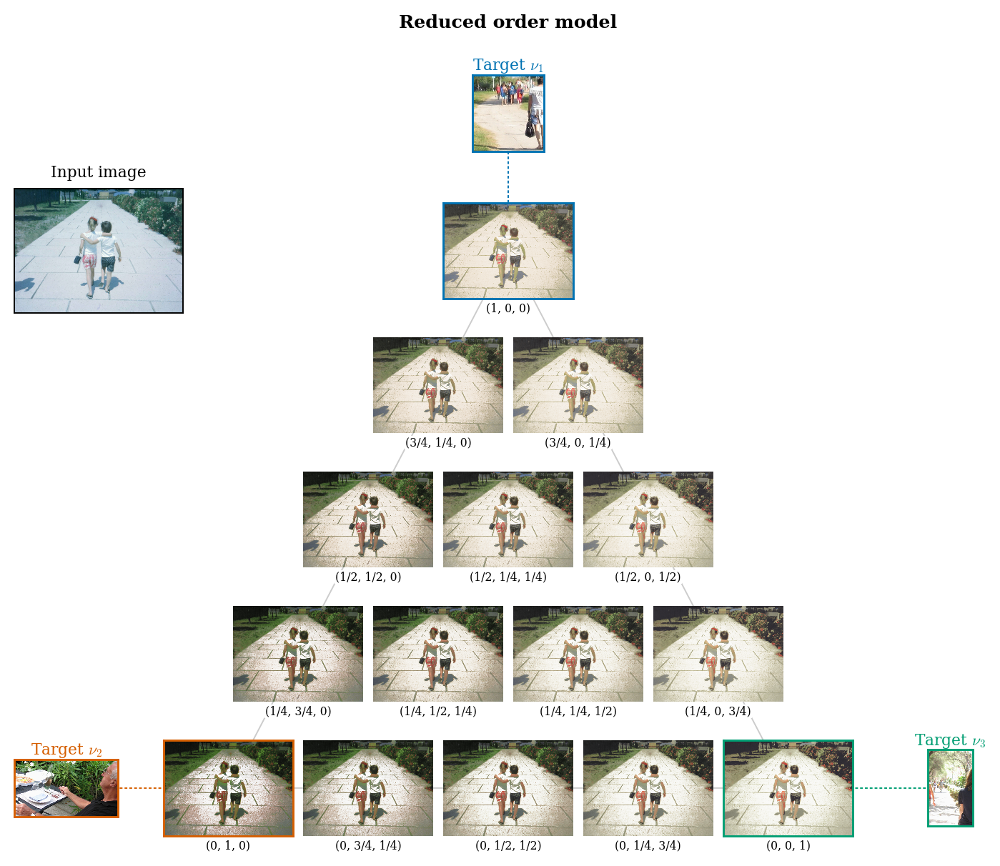

In [52]:
## Settings for the paper
plt.rcParams.update({
    'font.family': 'serif',
    'mathtext.fontset': 'cm',              # Computer Modern, matches LaTeX
    'axes.linewidth': 0.6,
    'pdf.fonttype': 42,                    # embed TrueType fonts (required by many publishers)
})
FIG_WIDTH = 7.0                            # inches: ~\textwidth of the paper
DPI = 600                                  # resolution of the thumbnails in the PDF
SHOW_ALPHA = True                          # weights (alpha0, alpha1, alpha2) under each result
COLORS = ['#0072B2', '#D55E00', '#009E73'] # palettes 1, 2, 3 (colour-blind safe)
STACK = 'vertical'                         # with 2 panels: 'vertical' (readable at \textwidth) or 'horizontal'
FILENAME = 'color_transfer_triangle'

panels = [('Reduced order model', out_rom)]
if out_full is not None:
    panels.insert(0, ('Full OT', out_full))

## Helpers
def thumb_hq(img, w_in):
    """uint8 image resampled (Lanczos) to w_in inches at DPI; never upsampled"""
    img = np.uint8(np.round(np.clip(img, 0, 1)*255))
    ih, iw = img.shape[:2]
    w_px = int(round(w_in*DPI))
    if w_px >= iw:
        return img
    return np.asarray(Image.fromarray(img).resize((w_px, max(1, round(w_px*ih/iw))), Image.LANCZOS))

def alpha_label(alpha):
    fr = [Fraction(float(a)).limit_denominator(12) for a in alpha]
    return '(' + ', '.join(str(f.numerator) if f.denominator == 1 else f'{f.numerator}/{f.denominator}' for f in fr) + ')'

## Layout (unit = width of one result image; results have the aspect ratio of the input)
r = u.shape[0] / u.shape[1]                # height / width of the results
gap_x, gap_y = 0.08, (0.30 if SHOW_ALPHA else 0.10)
dx, dy = 1 + gap_x, r + gap_y
L = nb_alpha - 1
s_tgt = 0.8                                # width of the target thumbnails
src_size = 1.3                             # width of the input image

def pos(alpha, o=(0, 0)):
    """centre of the result for weights alpha in the triangle with offset o"""
    return (o[0] + (alpha[2] - alpha[1])*L*dx/2, o[1] + alpha[0]*L*dy)

TRI = [pos(e) for e in np.eye(3)]          # corners: palette 1 top, 2 bottom-left, 3 bottom-right
(x_top, y_top), (x_bl, y_bl), (x_br, y_br) = TRI

def corners(o):
    """centres of the target thumbnails, just outside each corner"""
    return [(o[0] + x_top, o[1] + y_top + r/2 + 0.40 + s_tgt*r/2),
            (o[0] + x_bl - 0.85 - s_tgt/2, o[1] + y_bl),
            (o[0] + x_br + 0.85 + s_tgt/2, o[1] + y_br)]

# extent of one block (triangle + targets + title), then offsets of the panels
c0 = corners((0, 0))
blk_x0, blk_x1 = c0[1][0] - s_tgt/2, c0[2][0] + s_tgt/2
blk_y0, blk_y1 = y_bl - r/2 - (0.35 if SHOW_ALPHA else 0.1), c0[0][1] + s_tgt*r/2 + 0.55
if STACK == 'horizontal':
    offsets = [(i*(blk_x1 - blk_x0 + 0.3), 0) for i in range(len(panels))]
else:
    offsets = [(0, -i*(blk_y1 - blk_y0 + 0.1)) for i in range(len(panels))]
src_center = (blk_x0 + src_size/2, y_top)  # upper-left of the first triangle

xmin, xmax = blk_x0 - 0.05, offsets[-1][0] + blk_x1 + 0.05
ymin, ymax = offsets[-1][1] + blk_y0, blk_y1
W, H = xmax - xmin, ymax - ymin

# font sizes and line widths proportional to the image size, so the layout never overlaps
unit_pt = 72*FIG_WIDTH/W                   # points per layout unit
fs_alpha, fs_tgt, fs_panel = 0.087*unit_pt, 0.12*unit_pt, 0.14*unit_pt
lw = unit_pt/75
if fs_alpha < 5:
    print(f'Warning: alpha labels are only {fs_alpha:.1f} pt; use STACK="vertical" or SHOW_ALPHA=False')

## Figure
plt.close('all')
fig = plt.figure(figsize=(FIG_WIDTH, FIG_WIDTH*H/W))
fx = lambda x: (x - xmin)/W                # layout units -> figure fraction
fy = lambda y: (y - ymin)/H

def add_image(center, img, w=1.0, h=None, color=None, frame=1.2, label=None):
    """image fitted (aspect kept) in a box w x h centred on center; optional coloured frame and label below"""
    h = r*w if h is None else h
    ih, iw = img.shape[:2]
    if ih/iw > h/w: w = h*iw/ih            # shrink the box to the image aspect
    else:           h = w*ih/iw
    x, y = center
    ax = fig.add_axes([fx(x - w/2), fy(y - h/2), w/W, h/H])
    ax.imshow(thumb_hq(img, w*FIG_WIDTH/W), interpolation='none', aspect='auto')
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(color is not None)
        if color is not None:
            sp.set_color(color); sp.set_linewidth(frame*lw)
    if label is not None:
        ax.text(0.5, -0.04, label, transform=ax.transAxes, ha='center', va='top', fontsize=fs_alpha,
                bbox=dict(fc='white', ec='none', pad=0.3))
    return ax

def line(points, **kw):
    """polyline through points given in layout units, drawn behind the images"""
    xs, ys = zip(*points)
    fig.add_artist(plt.Line2D([fx(x) for x in xs], [fy(y) for y in ys],
                              transform=fig.transFigure, zorder=-1, **kw))

## Input image
ax = add_image(src_center, u/N, w=src_size, color='k', frame=0.8)
ax.set_title('Input image', fontsize=fs_tgt)

## Triangles
for (panel_title, outs), o in zip(panels, offsets):
    tri = [pos(e, o) for e in np.eye(3)]
    line(tri + tri[:1], color='0.8', lw=0.8*lw)                          # edges
    for k, (c, v) in enumerate(zip(corners(o), [v0, v1, v2])):           # target palettes
        line([c, tri[k]], color=COLORS[k], lw=0.8*lw, ls=(0, (2, 1.5)))
        ax = add_image(c, v/N, w=s_tgt, h=s_tgt*r, color=COLORS[k])
        ax.set_title(rf'Target $\nu_{k+1}$', fontsize=fs_tgt, color=COLORS[k], pad=2)
    for alpha, out in zip(tab_test_alpha, outs):                         # results
        k = int(np.argmax(alpha)) if np.max(alpha) > 0.999 else None     # corners get the palette colour
        add_image(pos(alpha, o), out, color=None if k is None else COLORS[k],
                  label=alpha_label(alpha) if SHOW_ALPHA else None)
    fig.text(fx(o[0] + x_top), fy(o[1] + blk_y1 - 0.08), panel_title, ha='center', va='top',
             fontsize=fs_panel, fontweight='bold')

fig.savefig(FILENAME + '.pdf', bbox_inches='tight', pad_inches=0.02)
fig.savefig(FILENAME + '.png', dpi=300, bbox_inches='tight', pad_inches=0.02)
plt.show()

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


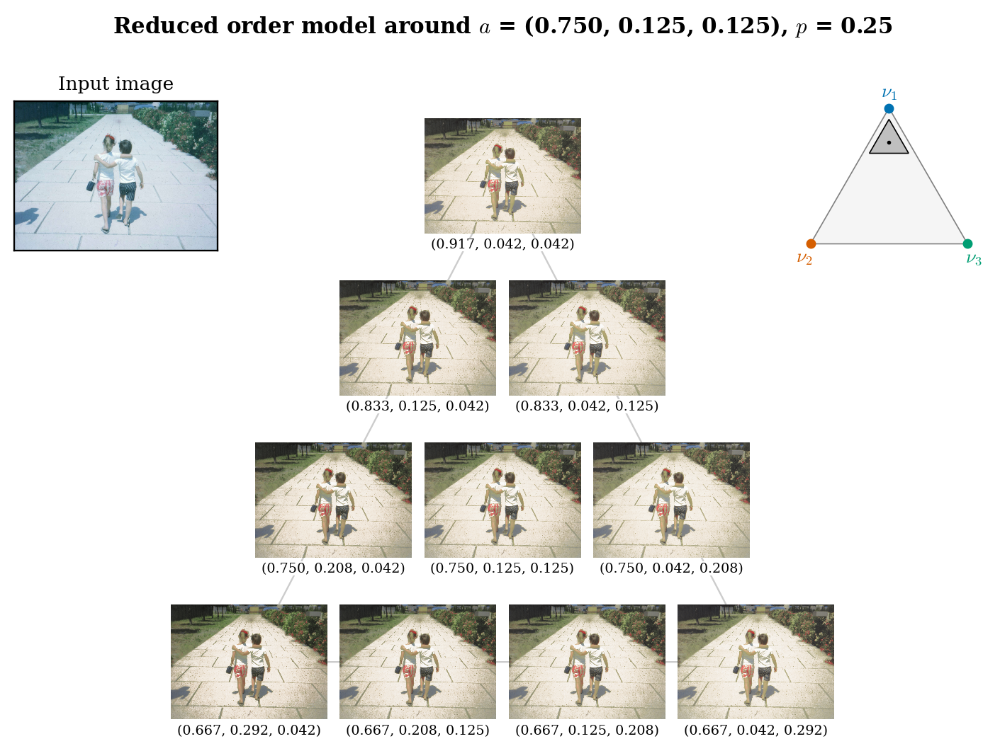

In [53]:
## Zoom on the simplex around a = (a0, a1, 1 - a0 - a1), reduced order model only
# needs: simplex_grid, apply_map (HF cell), rom_map (ROM cell), FIG_WIDTH, DPI, COLORS, thumb_hq (settings cell)
a0, a1 = 3/4, 1/8                          # centre a
p = 1/4                                    # size of the zoomed triangle (difference of weights between its corners)
nb_zoom = 4                                # results per edge
FILENAME_ZOOM = 'zoom_triangle'

a = np.array([a0, a1, 1 - a0 - a1])
if np.any(a < 0):
    raise ValueError(f'a = {a} is not in the simplex: weights must be >= 0')
p_max = 3*np.min(a)                        # largest p keeping the zoomed triangle inside the simplex
if p > p_max:
    print(f'p = {p} is too large for this a: reduced to p_max = {p_max:.4f}')
    p = p_max

## Weights: local grid beta on the unit triangle, mapped to the small triangle centred on a
#  alpha = a + p*(beta - 1/3)  -> corners a + p*(e_k - 1/3), same orientation as the big triangle
zoom_alpha = lambda beta: np.clip(a + p*(np.asarray(beta) - 1/3), 0, 1)
tab_beta = simplex_grid(nb_zoom)
tab_zoom_alpha = zoom_alpha(tab_beta)
out_zoom = [apply_map(rom_map(alpha)) for alpha in tab_zoom_alpha]

## Layout (unit = width of one result image)
rz = imsrc.shape[0] / imsrc.shape[1]
dxz, dyz = 1.08, rz + 0.30
Lz = nb_zoom - 1
src_size = ins_size = 1.3                  # widths of the input image and of the inset simplex
pos_z = lambda beta: ((beta[2] - beta[1])*Lz*dxz/2, beta[0]*Lz*dyz)
tri = [pos_z(e) for e in np.eye(3)]        # corners: top, bottom-left, bottom-right
(zx_top, zy_top), (zx_bl, zy_bl), (zx_br, zy_br) = tri
src_c = (zx_bl - 0.2 - src_size/2, zy_top) # input image, upper left
ins_c = (zx_br + 0.2 + ins_size/2, zy_top) # inset simplex, upper right

zxmin, zxmax = src_c[0] - src_size/2 - 0.05, ins_c[0] + ins_size/2 + 0.05
zymin, zymax = zy_bl - rz/2 - 0.35, zy_top + rz/2 + 0.75
ZW, ZH = zxmax - zxmin, zymax - zymin
upt = 72*FIG_WIDTH/ZW                      # points per layout unit
fs_alpha, fs_small, fs_title = 0.087*upt, 0.12*upt, 0.14*upt
lw = upt/75

ndig = max(2, int(np.ceil(-np.log10(p/Lz))) + 1)        # enough decimals to tell neighbours apart
fmt = lambda al: '(' + ', '.join(f'{x:.{ndig}f}' for x in al) + ')'

## Figure
plt.close('all')
figz = plt.figure(figsize=(FIG_WIDTH, FIG_WIDTH*ZH/ZW))
zfx = lambda x: (x - zxmin)/ZW             # layout units -> figure fraction
zfy = lambda y: (y - zymin)/ZH

def add_image_z(center, img, w=1.0, color=None, frame=1.0, label=None):
    """image of width w (aspect kept) centred on center; optional frame and label below"""
    ih, iw = img.shape[:2]
    h = w*ih/iw
    x, y = center
    ax = figz.add_axes([zfx(x - w/2), zfy(y - h/2), w/ZW, h/ZH])
    ax.imshow(thumb_hq(img, w*FIG_WIDTH/ZW), interpolation='none', aspect='auto')
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(color is not None)
        if color is not None:
            sp.set_color(color); sp.set_linewidth(frame*lw)
    if label is not None:
        ax.text(0.5, -0.04, label, transform=ax.transAxes, ha='center', va='top', fontsize=fs_alpha,
                bbox=dict(fc='white', ec='none', pad=0.3))
    return ax

# edges of the zoomed triangle (behind the images)
xs, ys = zip(*(tri + tri[:1]))
figz.add_artist(plt.Line2D([zfx(x) for x in xs], [zfy(y) for y in ys],
                           transform=figz.transFigure, color='0.8', lw=0.8*lw, zorder=-1))

# input image and results
ax = add_image_z(src_c, imsrc, w=src_size, color='k', frame=0.8)
ax.set_title('Input image', fontsize=fs_small)
for beta, alpha, out in zip(tab_beta, tab_zoom_alpha, out_zoom):
    add_image_z(pos_z(beta), out, label=fmt(alpha))

# inset: where the zoomed triangle sits in the full simplex
bary = lambda al: ((al[2] - al[1])/2, al[0]*np.sqrt(3)/2)      # same orientation as the figure
ax = figz.add_axes([zfx(ins_c[0] - ins_size/2), zfy(ins_c[1] - ins_size*0.45), ins_size/ZW, ins_size*0.9/ZH])
big = [bary(e) for e in np.eye(3)]
ax.fill(*zip(*big), fc='0.96', ec='0.5', lw=0.6)
ax.fill(*zip(*[bary(zoom_alpha(e)) for e in np.eye(3)]), fc='0.75', ec='k', lw=0.6)
ax.plot(*bary(a), 'k.', ms=2)
for k, (xy, va, dxy) in enumerate(zip(big, ['bottom', 'top', 'top'], [(0, .04), (-.04, -.03), (.04, -.03)])):
    ax.plot(*xy, 'o', ms=4, color=COLORS[k])
    ax.text(xy[0] + dxy[0], xy[1] + dxy[1], rf'$\nu_{k+1}$', color=COLORS[k], ha='center', va=va, fontsize=fs_small)
ax.set_xlim(-0.62, 0.62); ax.set_ylim(-0.15, np.sqrt(3)/2 + 0.15)
ax.set_aspect('equal'); ax.axis('off')

figz.text(0.5, zfy(zymax - 0.08), rf'Reduced order model around $a$ = {fmt(a)}, $p$ = {p:g}',
          ha='center', va='top', fontsize=fs_title, fontweight='bold')

figz.savefig(FILENAME_ZOOM + '.pdf', dpi=DPI, bbox_inches='tight', pad_inches=0.02)
figz.savefig(FILENAME_ZOOM + '.png', dpi=DPI, bbox_inches='tight', pad_inches=0.02)
plt.show()

In [54]:
### Final glow up: using a filter to get rid of the noise as in Storimage notebook

## Guided filter (He et al.): filters p using the structure of the guide I
def guided_filter(p, I, r, eps):
    box = lambda x: sd.uniform_filter(x, size=2*r+1, mode='reflect')   # mean over a (2r+1)x(2r+1) window
    mean_I, mean_p = box(I), box(p)
    var_I  = box(I*I) - mean_I**2
    cov_Ip = box(I*p) - mean_I*mean_p
    a = cov_Ip / (var_I + eps)
    b = mean_p - a*mean_I
    return box(a)*I + box(b)

## Choose the weights (alpha0, alpha1, alpha2) of the picture to post-process
alpha_sel = np.array([0.667, 0.125, 1-0.667-0.125])
r_gf, eps_gf = 20, 1e-4             # radius and regularization of the guided filter (as in the notebook)

out = rom_image(alpha_sel)          # reduced order model (use full_ot_map + apply_map for full OT)

## Postprocessing: T(g(u)) = u + Y_u(g(u) - u)
diff = out - imsrc
out2 = np.zeros_like(imsrc)
for i in range(3):
    out2[:,:,i] = guided_filter(diff[:,:,i], imsrc[:,:,i], r_gf, eps_gf)
out_reg = np.clip(imsrc + out2, 0, 1)

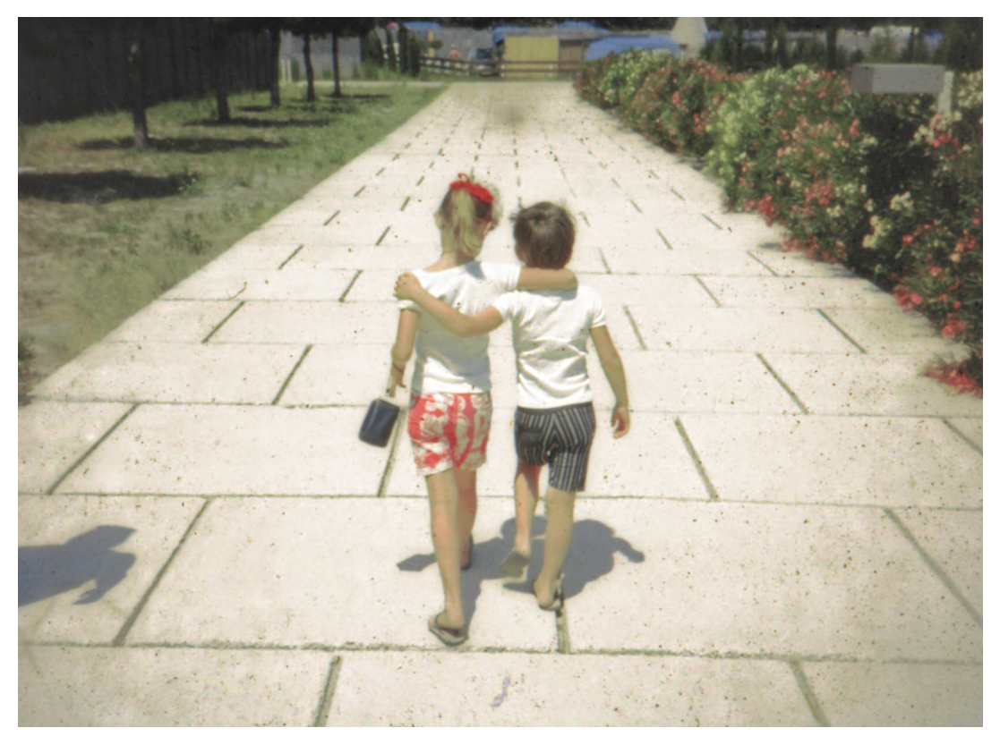

In [25]:
## Display
label = '(' + ', '.join(f'{x:.2f}' for x in alpha_sel) + ')'
h_img, w_img = out_reg.shape[:2]
fig, ax = plt.subplots(figsize=(7, 7*h_img/w_img))     # one axis, same aspect ratio as the picture
ax.imshow(out_reg)
ax.axis('off')                                          # no ticks or frame around the picture
fig.savefig('final.pdf', bbox_inches='tight', pad_inches=0.02)
plt.show()

#### Numerical analysis (figures from the paper)

In [57]:
### Function to build ROM

def build_rb(n):
    """offline phase: snapshots on simplex_grid(n), their costs Wc, map terms and matrix K"""
    A = simplex_grid(n)
    snaps = [sinkhorn(alpha) for alpha in A]
    terms = [map_terms(*s) for s in snaps]
    return dict(A=A,
                Wc=np.array([transport_cost(a, b) for a, b, _ in snaps]),
                sum_j=np.stack([t[0] for t in terms], axis=-1),       # (N,N,N,3,P)
                sum_wght=np.stack([t[1] for t in terms], axis=-1),    # (N,N,N,P)
                K=np.vstack([A[:, 1:].T, np.ones(len(A))]))

In [60]:
## HF vs reduced bases: timings on random parameters (table) + pictures for one parameter (figure cell)
# needs: cell A (HF), cell B (ROM)
alpha_test = np.array([0.667, 0.125, 1 - 0.667 - 0.125])    # parameter shown in the figure
n_test = 10                                # number of random parameters for the timings
rng = np.random.default_rng(0)             # fixed seed -> reproducible
tab_alpha_rand = rng.dirichlet([1, 1, 1], size=n_test)      # uniform on the triangle, each row sums to 1
P_list = [2, 3, 4, 5]                      # points per edge -> 3, 6, 10, 15 snapshots

def online_times(transfer):
    """run times of transfer(alpha) on the random parameters (after one warm-up run)"""
    transfer(tab_alpha_rand[0])
    times = []
    for alpha in tab_alpha_rand:
        t0 = time.perf_counter()
        transfer(alpha)
        times.append(time.perf_counter() - t0)
    return np.mean(times), np.std(times)

fmt_t = lambda t: f'{t:.2f} s' if t >= 0.1 else f'{1e3*t:.1f} ms'   # times in the picture titles

## High fidelity
hf = lambda alpha: apply_map(full_ot_map(alpha))
t_hf, s_hf = online_times(hf)
rows = [dict(Method='High fidelity', Snapshots='-', Offline_s=0.0, Online_mean_s=t_hf, Online_std_s=s_hf,
             Break_even='-', Speed_up=1.0)]
outs, titles = [hf(alpha_test)], [f'High fidelity\n{fmt_t(t_hf)}']

## Reduced bases: offline once, online on every random parameter
for P in P_list:
    t0 = time.perf_counter()
    rb = build_rb(P)
    t_off = time.perf_counter() - t0
    rom = lambda alpha: apply_map(rom_map(alpha, rb))
    t_on, s_on = online_times(rom)
    # break-even: smallest number of queries n with  t_off + n*t_on <= n*t_hf
    n_be = math.ceil(t_off / (t_hf - t_on)) if t_hf > t_on else np.inf
    n = len(rb['A'])
    rows.append(dict(Method=f'RB, {n} snapshots', Snapshots=n, Offline_s=t_off,
                     Online_mean_s=t_on, Online_std_s=s_on, Break_even=n_be, Speed_up=t_hf/t_on))
    outs.append(rom(alpha_test))
    titles.append(f'RB, {n} snapshots\n{fmt_t(t_on)}')
    del rb                                 # frees the memory of this basis

## Table
table = pd.DataFrame(rows).set_index('Method')
pd.options.display.float_format = '{:.4g}'.format
print(f'{n_test} random parameters, N = {N}')
print(table.to_string())
print(table.to_latex(float_format='%.3g'))   # LaTeX version, ready for the paper

10 random parameters, N = 64
                 Snapshots  Offline_s  Online_mean_s  Online_std_s Break_even  Speed_up
Method                                                                                 
High fidelity            -          0          6.826       0.04352          -         1
RB, 3 snapshots          3      19.85         0.1726      0.004465          3     39.54
RB, 6 snapshots          6      39.82         0.1737      0.002596          6     39.29
RB, 10 snapshots        10      67.22         0.1783     0.0007821         11     38.29
RB, 15 snapshots        15      101.4         0.1785      0.001623         16     38.25
\begin{tabular}{llrrrlr}
\toprule
 & Snapshots & Offline_s & Online_mean_s & Online_std_s & Break_even & Speed_up \\
Method &  &  &  &  &  &  \\
\midrule
High fidelity & - & 0 & 6.83 & 0.0435 & - & 1 \\
RB, 3 snapshots & 3 & 19.8 & 0.173 & 0.00447 & 3 & 39.5 \\
RB, 6 snapshots & 6 & 39.8 & 0.174 & 0.0026 & 6 & 39.3 \\
RB, 10 snapshots & 10 & 67.2 & 0.17

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


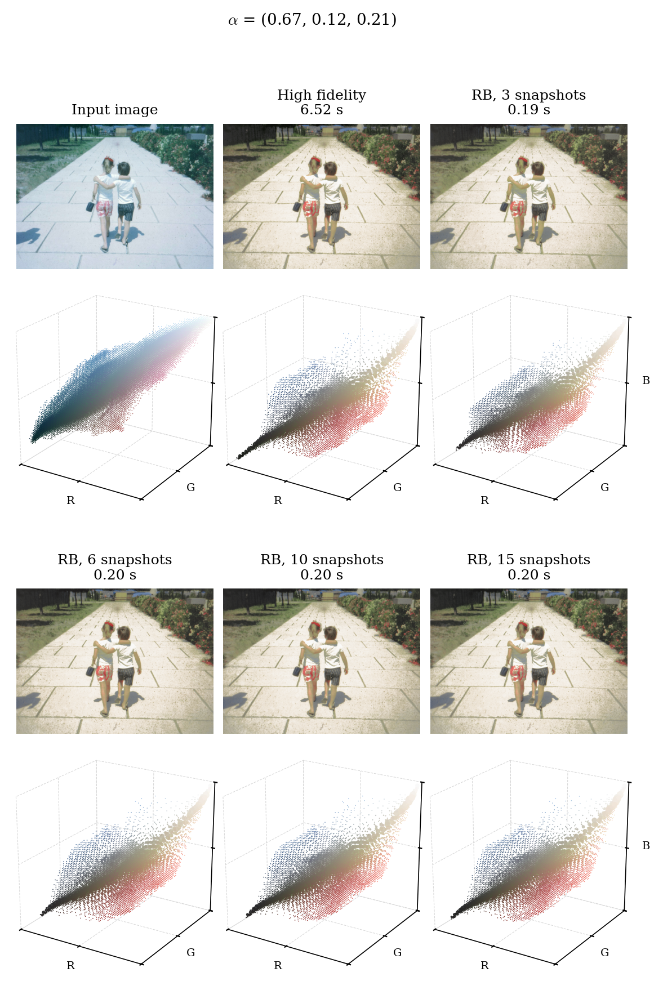

In [22]:
# Comparison of the results for different values
alpha_test = np.array([0.667, 0.125, 1-0.667-0.125])

## Pictures + colour clouds below each picture (second file)
imgs   = [imsrc] + outs
labels = ['Input image'] + titles
ncols  = math.ceil(len(imgs) / 2)
r = imsrc.shape[0] / imsrc.shape[1]                    # height / width of the pictures
fig_w = FIG_WIDTH                                       # inches: ~\textwidth of the paper
cell_w = fig_w / ncols
fig = plt.figure(figsize=(fig_w, 2*cell_w*(r + 1.0) + 1.6))
gs = GridSpec(5, ncols, figure=fig, height_ratios=[r, 1.0, 0.25, r, 1.0], hspace=0.12, wspace=0.05)   # row 2: spacer
for i, (img, title) in enumerate(zip(imgs, labels)):
    row, col = 3*(i // ncols), i % ncols               # picture rows 0 and 3, clouds rows 1 and 4
    ax = fig.add_subplot(gs[row, col])
    ax.imshow(np.clip(img, 0, 1))
    ax.set_title(title, fontsize=9)
    ax.axis('off')
    img_q = np.floor(np.clip(img, 0, 1)*(N-0.01))      # same N x N x N binning as the histograms
    ax3 = fig.add_subplot(gs[row + 1, col], projection='3d')
    plot_color_cloud(ax3, img_q, N, max_size=25)
    ax3.set_xticklabels([]); ax3.set_yticklabels([]); ax3.set_zticklabels([])   # too small to read at this size
    ax3.set_xlabel('R', fontsize=7, labelpad=-14); ax3.set_ylabel('G', fontsize=7, labelpad=-14)
    ax3.set_zlabel('B', fontsize=7, labelpad=-14)
fig.suptitle(r'$\alpha$ = (' + ', '.join(f'{a:.2f}' for a in alpha_test) + ')', fontsize=10)
fig.savefig('hf_vs_rb_clouds.pdf', dpi=300, bbox_inches='tight', pad_inches=0.02)
plt.show()